# Measured importance–latency distributions

Compare Paper and Tiles using the recorded masks and timings from
[03_02](03_02_measure_latency.ipynb). Budgets are matched by requested row fraction;
Paper may select fewer rows. Retained importance is the selected percentage of
captured activation importance.

In [1]:
from math             import ceil
from pathlib          import Path
from matplotlib.lines import Line2D

import json

import numpy             as np
import pandas            as pd
import matplotlib.pyplot as plt

## 1. Data

Choose `METRIC`: `io_ms`, `selection_ms`, or `wall_ms`. Compute the median of
that column over repetitions for each case, then join its recorded mask metadata.

Latency is in ms. Selection includes Paper's GPU sort and score transfers.
Wall time is recorded from prepared CPU importance through completion of the
CPU read. Convert the tile reference size recorded in `environment.json`
from KiB to rows.

In [2]:
METRIC = "wall_ms"  # "io_ms", "selection_ms" or "wall_ms"
PAPER  = "Paper greedy (GPU sort)"

In [3]:
cases       = pd.read_csv("cases.csv", float_precision="round_trip")
timings     = pd.read_csv("timings.csv", float_precision="round_trip")
environment = json.loads(Path("environment.json").read_text())

In [4]:
# One metadata row and one sample per case and repetition.
assert cases.case_id.is_unique
assert not timings.duplicated(["case_id", "repeat"]).any()
assert set(timings.case_id) == set(cases.case_id)

repeats = timings.groupby("case_id").size()
assert repeats.eq(environment["repeats"]).all()

latency = timings[METRIC]
assert np.isfinite(latency).all() and (latency > 0).all()

In [5]:
medians = timings.groupby("case_id")[METRIC].median()
medians = medians.rename("latency")

results = cases.join(
    medians,
    on       = "case_id",
    validate = "one_to_one",
)

In [6]:
results = results.rename(columns={
    "tile_rows"    : "tile_width",
    "retained_pct" : "retained",
})

# Profile boundary: KiB -> rows.
row_kib  = results.d * environment["dtype_bytes"] / 1024
boundary = environment["tile_boundary_kib"]
results["saturation_rows"] = boundary / row_kib

assert not results.duplicated(["n", "d", "method", "fraction", "trace_id"]).any()

## 2. Trace summaries

Group cases by shape, method, and requested budget. Compute marginal medians
of case latency and retained importance across traces, with equal weight per trace.
Check that methods contain the same budgets and trace IDs.

In [7]:
class TracePoints:
    def __init__(self, rows):
        self.samples = (
            rows.set_index("trace_id")[["latency", "retained"]]
            .sort_index()
        )

        self.median = self.samples.quantile(0.5)

In [8]:
class MethodResults:
    def __init__(self, rows):
        self.tile_width = rows.tile_width.iloc[0]
        self.budgets    = {}

        for fraction, group in rows.groupby("fraction"):
            self.budgets[fraction] = TracePoints(group)

    def median_curve(self):
        medians = {}

        for fraction, group in self.budgets.items():
            medians[fraction] = group.median

        return pd.DataFrame.from_dict(medians, orient="index")

    def assert_comparable_to(self, baseline):
        assert self.budgets.keys() == baseline.budgets.keys()

        for fraction, group in self.budgets.items():
            current_index  = group.samples.index
            baseline_index = baseline.budgets[fraction].samples.index

            assert current_index.equals(baseline_index)

    def difference_from(self, baseline):
        self.assert_comparable_to(baseline)
        differences = {}

        for fraction, group in self.budgets.items():
            reference = baseline.budgets[fraction].samples
            differences[fraction] = group.samples - reference

        return pd.concat(differences, names=["fraction"])

In [9]:
class ShapeResults:
    def __init__(self, shape, rows):
        self.shape           = shape
        self.saturation_rows = rows.saturation_rows.iloc[0]
        self.trace_count     = rows.trace_id.nunique()

        # Baselines, then decreasing tile width
        groups = rows.groupby("method")

        widths = groups.tile_width.first()
        widths = widths.sort_values(
            ascending   = False,
            na_position = "first",
        )

        self.methods = {}

        for name in widths.index:
            method_rows = groups.get_group(name)
            self.methods[name] = MethodResults(method_rows)

In [10]:
points = {}

for shape, rows in results.groupby(["n", "d"]):
    points[shape] = ShapeResults(shape, rows)

In [11]:
points[(896, 896)].methods[PAPER].budgets[0.5].samples.head()

,latency,retained
trace_id,,
0,1.507432,57.780937
14,1.627336,54.656250
31,1.640335,63.955133
45,1.872015,61.605504
63,1.499301,59.007767


In [12]:
# Matched budgets and traces
for result in points.values():
    baseline = result.methods[PAPER]

    for method in result.methods.values():
        method.assert_comparable_to(baseline)

## 3. Plot

Points show trace observations; color identifies the requested fraction.
Solid lines connect marginal medians in budget order. The dotted line shows
the Paper reference. These summaries do not define a Pareto frontier.

Baseline/coarse and fine panels use separate logarithmic latency ranges
and a common importance range. To change `METRIC`, rerun from the Data section.

In [13]:
latency_label = {
    "io_ms"        : "Measured I/O time (ms)",
    "selection_ms" : "Measured selection time (ms)",
    "wall_ms"      : "Measured wall time (ms)",
}[METRIC]

In [14]:
color_scale = plt.cm.ScalarMappable(
    norm = plt.Normalize(results.fraction.min(), results.fraction.max()),
    cmap = "viridis",
)

def draw_observations(ax, method):
    for fraction, group in method.budgets.items():
        samples = group.samples
        ax.scatter(
            samples.latency,
            samples.retained,
            color = color_scale.to_rgba(fraction),
            s     = 9,
            alpha = 0.16,
        )

def draw_median_curve(ax, method):
    curve = method.median_curve()
    ax.plot(
        curve.latency,
        curve.retained,
        color = "black"
    )
    ax.scatter(
        curve.latency,
        curve.retained,
        c          = color_scale.to_rgba(curve.index),
        edgecolors = "black",
        zorder     = 3,
    )

def draw_method(ax, method, baseline=None):
    if baseline is not None:
        ax.plot(
            baseline.latency,
            baseline.retained,
            ":",
            color = "gray"
        )

    draw_observations(ax, method)
    draw_median_curve(ax, method)

In [15]:
def draw_legend(fig):
    reference = Line2D(
        (), (),
        label = "Paper median",

        color     = "gray",
        linestyle = ":",
    )

    observations = Line2D(
        (), (),
        label = "Trace observations",

        color      = "gray",
        linestyle  = "none",
        marker     = "o",
        markersize = 3,
        alpha      = 0.16,
    )

    medians = Line2D(
        (), (),
        label = "Marginal medians",

        color = "black",
    )

    fig.legend(
        handles = (reference, observations, medians),
        loc     = "outside lower center",
        ncol    = 3,
    )

In [16]:
def draw_shape(result):
    n, d     = result.shape
    s        = result.saturation_rows
    methods  = result.methods
    baseline = methods[PAPER].median_curve()

    ncols = 4
    nrows = ceil(len(methods) / ncols)
    fig   = plt.figure(figsize=(4 * ncols, 3 * nrows), layout="constrained")

    shared_x = {}

    for position, (name, method) in enumerate(methods.items(), 1):
        B = method.tile_width

        # Panel settings
        if pd.isna(B):
            title      = name
            axis_group = "baseline/coarse"
        elif B < s:
            title      = f"{name}\nB = {B:g} (< s)"
            axis_group = "fine"
        else:
            title      = f"{name}\nB = {B:g} (≥ s)"
            axis_group = "baseline/coarse"

        reference = None
        if name != PAPER:
            reference = baseline

        # Panel
        ax = fig.add_subplot(
            nrows, ncols, position,
            sharex = shared_x.get(axis_group),
        )
        shared_x[axis_group] = ax

        draw_method(
            ax, method,
            baseline = reference,
        )
        ax.set(
            title  = title,
            xscale = "log",
            ylim   = (0, 102),
            xlabel = latency_label,
        )

    # Shared guides
    draw_legend(fig)
    fig.colorbar(color_scale, ax=fig.axes, label="Requested fraction")
    fig.supylabel("Retained importance (%)")

    title    = f"{n} x {d} · {result.trace_count} traces · s = {s:.2f} rows"
    subtitle = "Baseline/coarse and fine panels use separate log-latency ranges"
    fig.suptitle(f"{title}\n{subtitle}")
    return fig

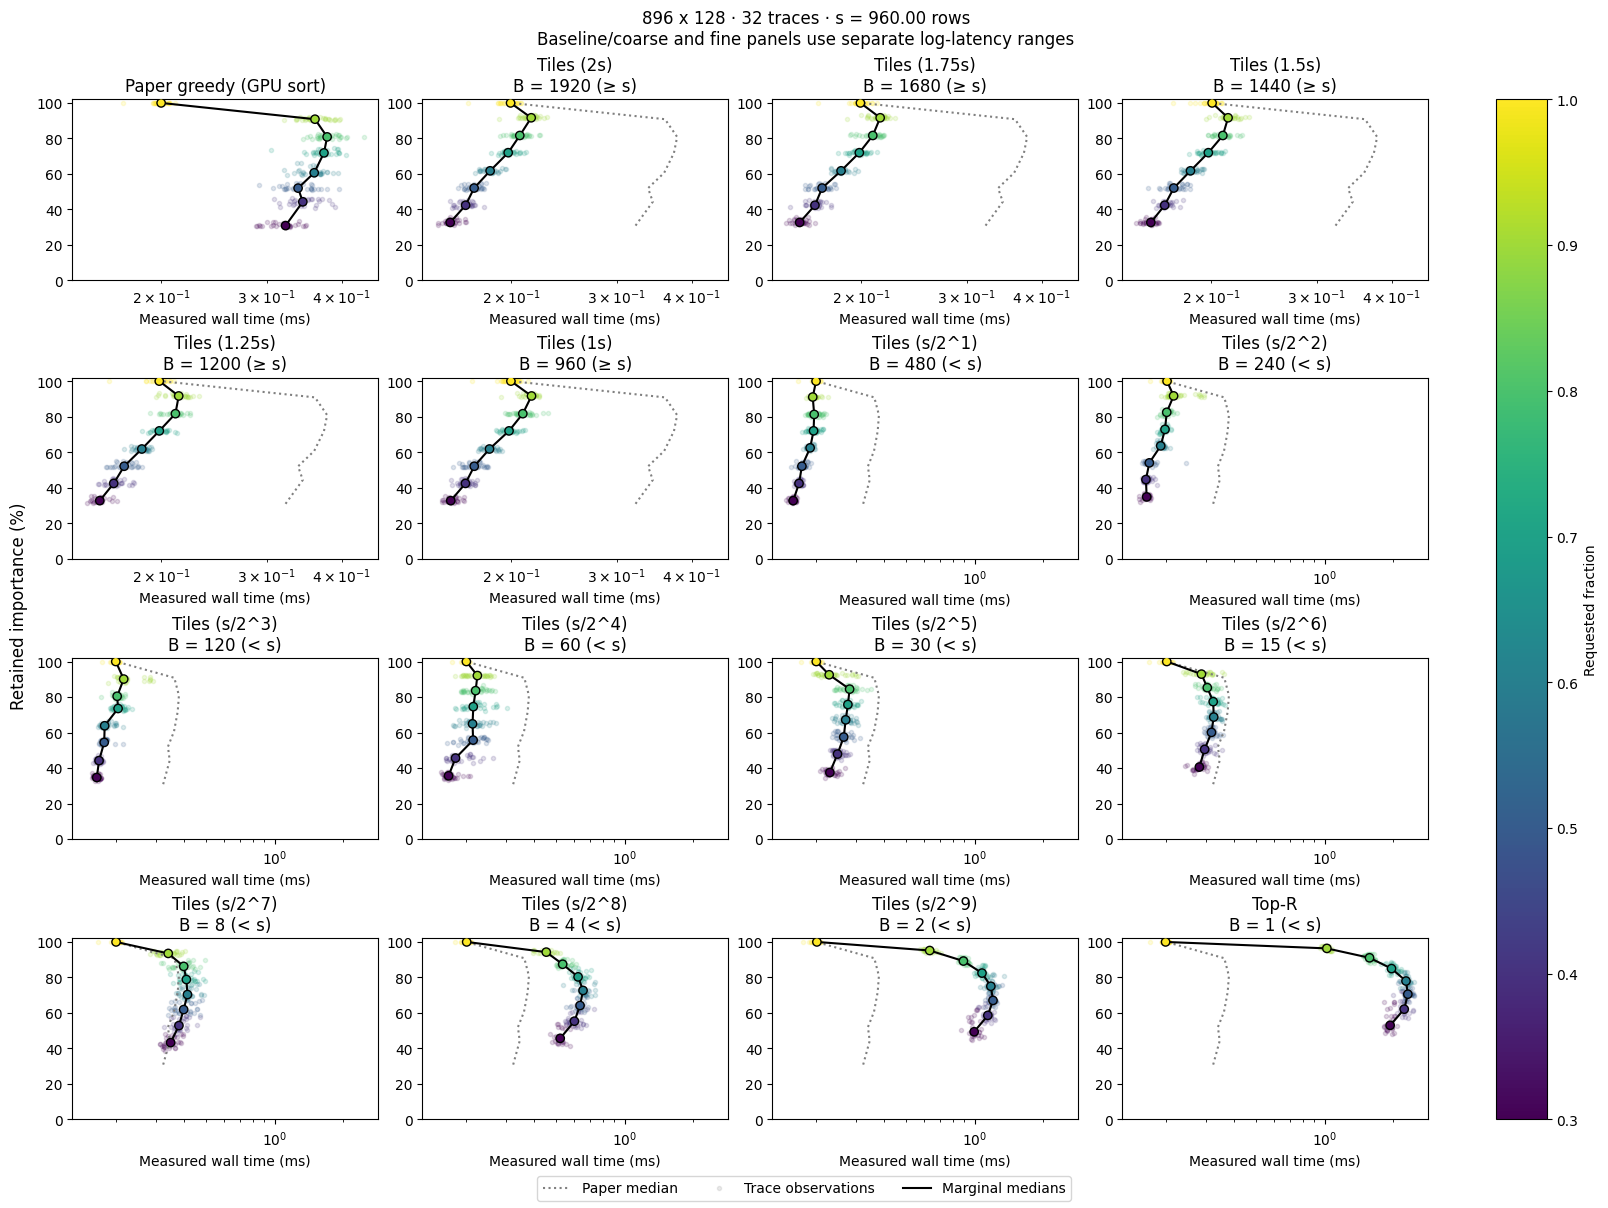

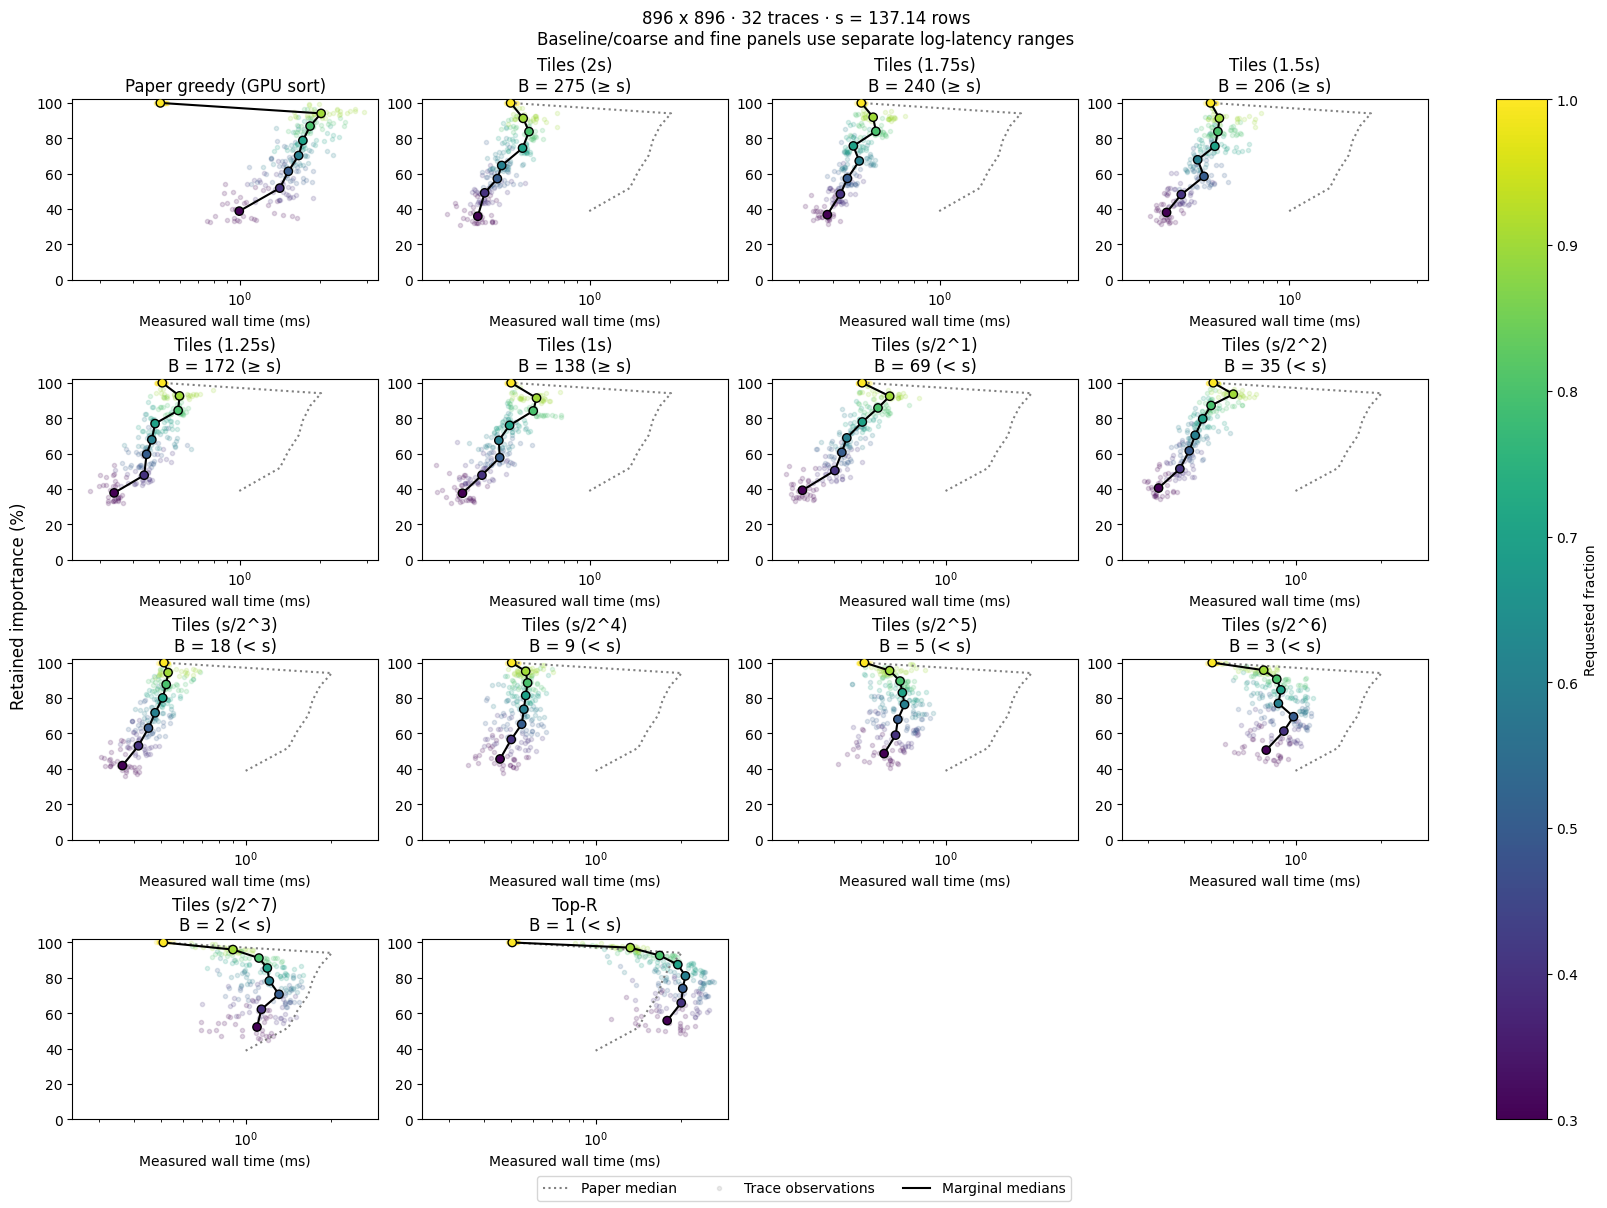

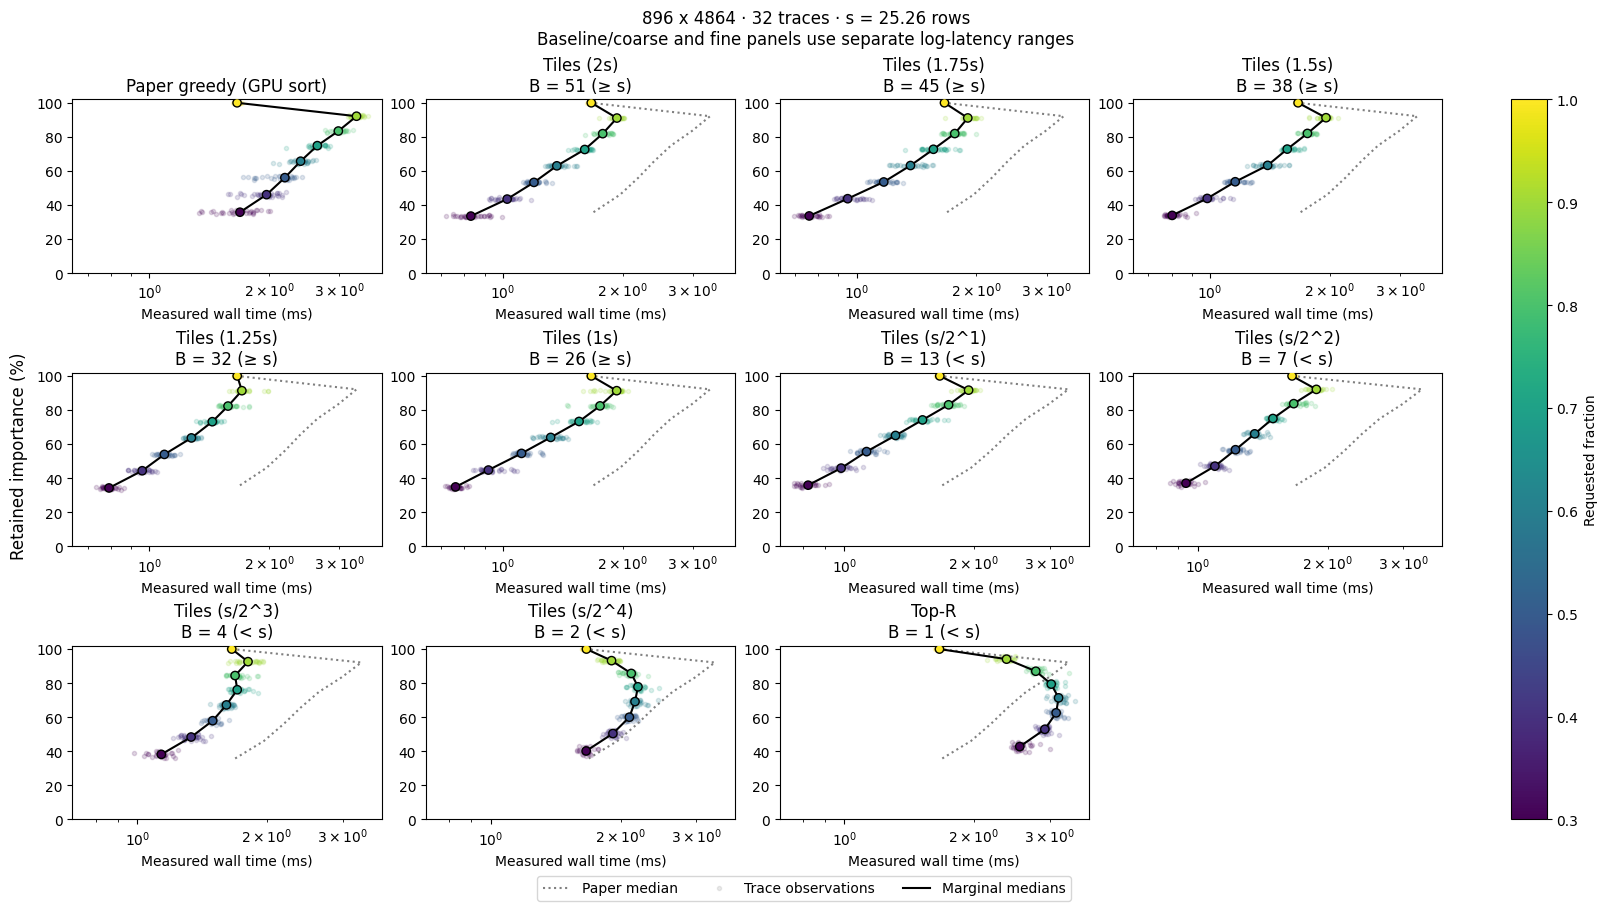

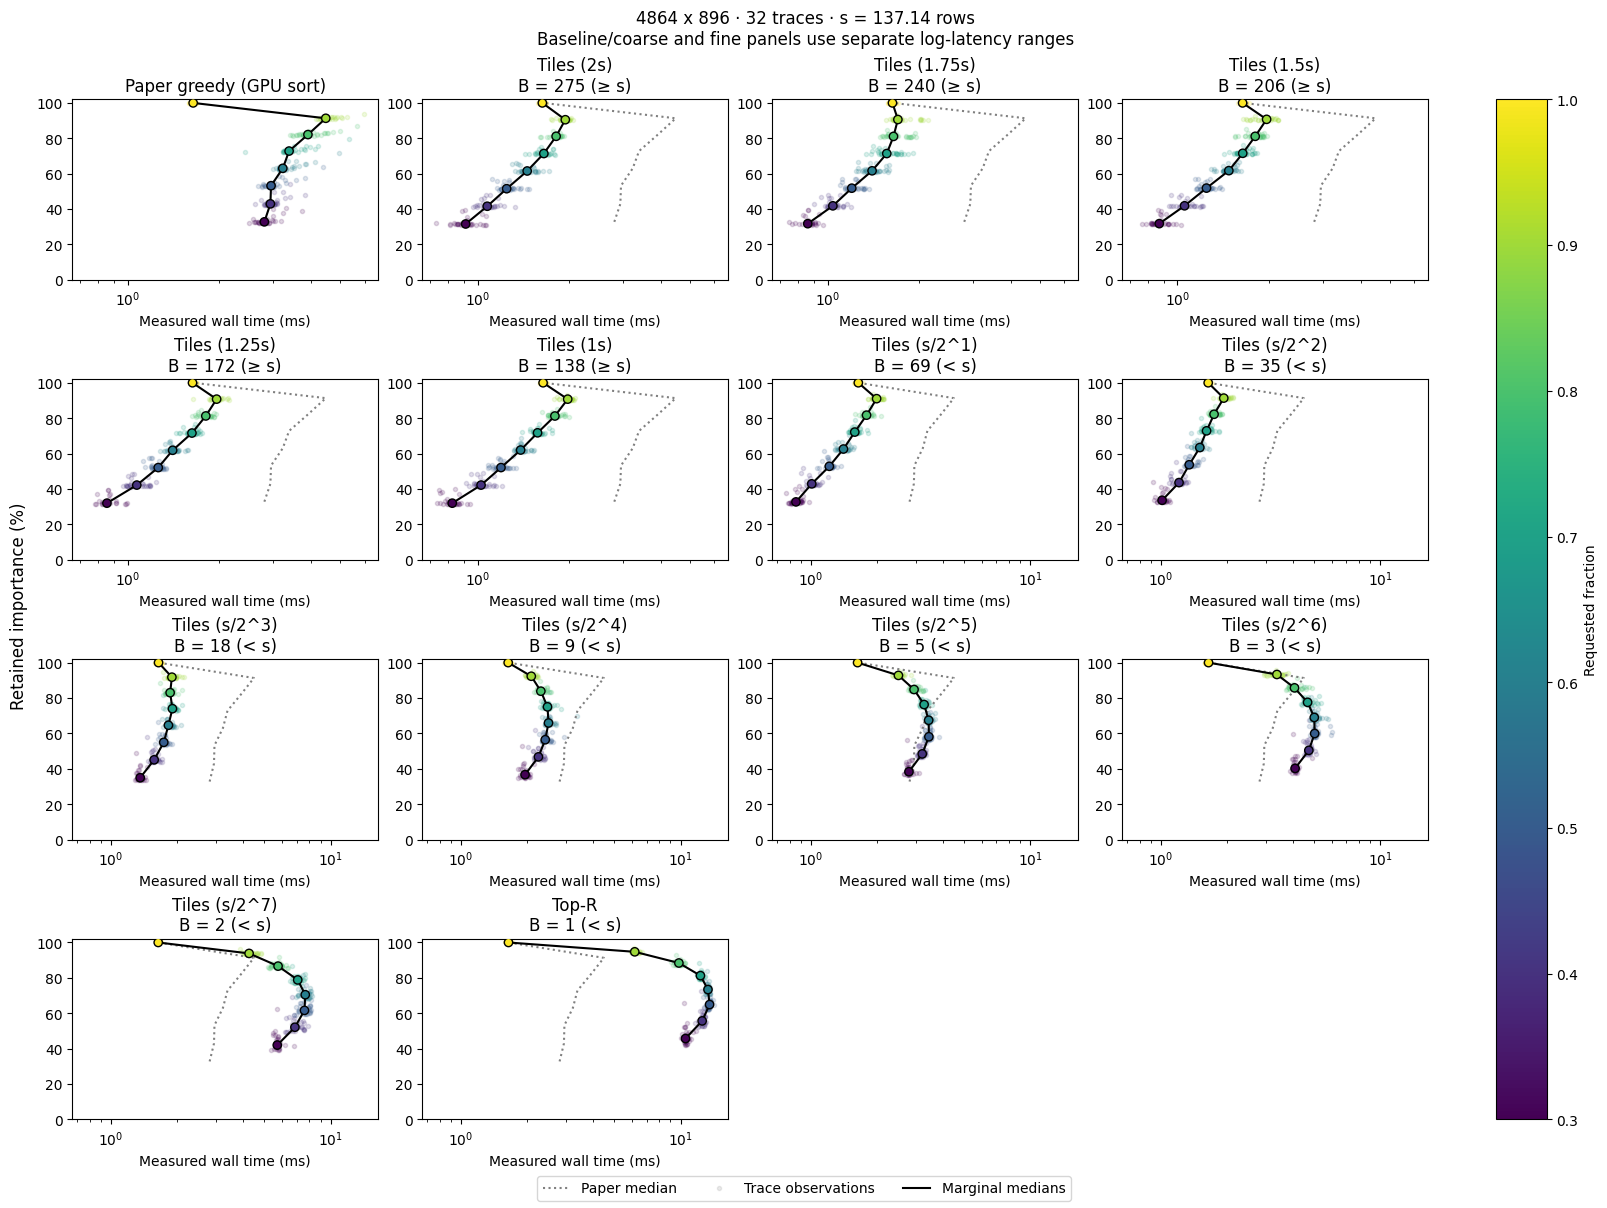

In [17]:
for result in points.values():
    fig = draw_shape(result)

    plt.show()
    plt.close(fig)

## 4. Paired differences

Subtract Paper's value within each trace and requested budget. For each shape
and method, report the median over all trace–budget pairs, including full selection.
Negative latency differences indicate faster execution; importance differences
are in percentage points.

Pairing fixes the requested budget. Selected row count and retained importance
may differ between methods.

In [18]:
records = []

for result in points.values():
    n, d     = result.shape
    baseline = result.methods[PAPER]

    for name, method in result.methods.items():
        if name == PAPER:
            continue

        differences = method.difference_from(baseline)
        median      = differences.median()

        records.append({
            "n"                 : n,
            "d"                 : d,
            "method"            : name,
            "tile_width"        : method.tile_width,
            "delta_latency_ms"  : median.latency,
            "delta_retained_pp" : median.retained,
        })

comparisons = pd.DataFrame(records)
comparisons = comparisons.set_index(["n", "d", "method"])
comparisons.round(4)

tile_width  delta_latency_ms  delta_retained_pp
n    d    method                                                        
896  128  Tiles (2s)         1920.0           -0.1650             0.5203
          Tiles (1.75s)      1680.0           -0.1646             0.5203
          Tiles (1.5s)       1440.0           -0.1643             0.5203
          Tiles (1.25s)      1200.0           -0.1641             0.5203
          Tiles (1s)          960.0           -0.1632             0.5203
          Tiles (s/2^1)       480.0           -0.1665             0.0965
          Tiles (s/2^2)       240.0           -0.1668             1.0099
          Tiles (s/2^3)       120.0           -0.1610             1.0880
          Tiles (s/2^4)        60.0           -0.1427             2.2841
          Tiles (s/2^5)        30.0           -0.0886             4.1460
          Tiles (s/2^6)        15.0           -0.0406             6.0307
          Tiles (s/2^7)         8.0            0.0210             8.0220
          Tiles (s/2^8)         4.0            0.2102             9.7751
          Tiles (s/2^9)         2.0            0.6842            12.1361
          Top-R                 1.0            1.6128            14.4055
     896  Tiles (2s)          275.0           -1.0848            -2.3191
          Tiles (1.75s)       240.0           -1.0905            -1.6957
          Tiles (1.5s)        206.0           -1.0998            -2.2359
          Tiles (1.25s)       172.0           -1.0902            -1.9215
          Tiles (1s)          138.0           -1.0951            -1.8209
          Tiles (s/2^1)        69.0           -1.1044            -0.7562
          Tiles (s/2^2)        35.0           -1.1215             0.0000
          Tiles (s/2^3)        18.0           -1.0919             0.8640
          Tiles (s/2^4)         9.0           -1.0185             2.1589
          Tiles (s/2^5)         5.0           -0.8959             3.3641
          Tiles (s/2^6)         3.0           -0.6574             4.6330
          Tiles (s/2^7)         2.0           -0.3530             5.7767
          Top-R                 1.0            0.1814             8.0743
     4864 Tiles (2s)           51.0           -1.0077            -1.8825
          Tiles (1.75s)        45.0           -1.0255            -1.8473
          Tiles (1.5s)         38.0           -1.0168            -1.6764
          Tiles (1.25s)        32.0           -1.1131            -1.4959
          Tiles (1s)           26.0           -1.0667            -1.1106
          Tiles (s/2^1)        13.0           -1.0631            -0.3360
          Tiles (s/2^2)         7.0           -1.0172             0.2883
          Tiles (s/2^3)         4.0           -0.7849             1.2205
          Tiles (s/2^4)         2.0           -0.1831             2.8697
          Top-R                 1.0            0.5660             4.9077
4864 896  Tiles (2s)          275.0           -1.8425            -1.2547
          Tiles (1.75s)       240.0           -1.8928            -1.0723
          Tiles (1.5s)        206.0           -1.8586            -1.0161
          Tiles (1.25s)       172.0           -1.8950            -0.9047
          Tiles (1s)          138.0           -1.9050            -0.8329
          Tiles (s/2^1)        69.0           -1.9043            -0.3332
          Tiles (s/2^2)        35.0           -1.7808             0.2723
          Tiles (s/2^3)        18.0           -1.4540             1.2362
          Tiles (s/2^4)         9.0           -0.8499             2.3984
          Tiles (s/2^5)         5.0           -0.0235             3.6744
          Tiles (s/2^6)         3.0            1.2124             5.0164
          Tiles (s/2^7)         2.0            3.0696             6.2224
          Top-R                 1.0            8.2691             8.7219